In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("/content/Dataset .csv")

In [3]:
print("Dataset Preview:")
print(df.head())


Dataset Preview:
   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong C

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [4]:
price_counts = df['Price range'].value_counts().sort_index()

print("\nRestaurant Count by Price Range:")
print(price_counts)


Restaurant Count by Price Range:
Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64


In [5]:
most_common = price_counts.idxmax()

print("\nMost Common Price Range:", most_common)
print("Number of Restaurants:", price_counts.max())


Most Common Price Range: 1
Number of Restaurants: 4444


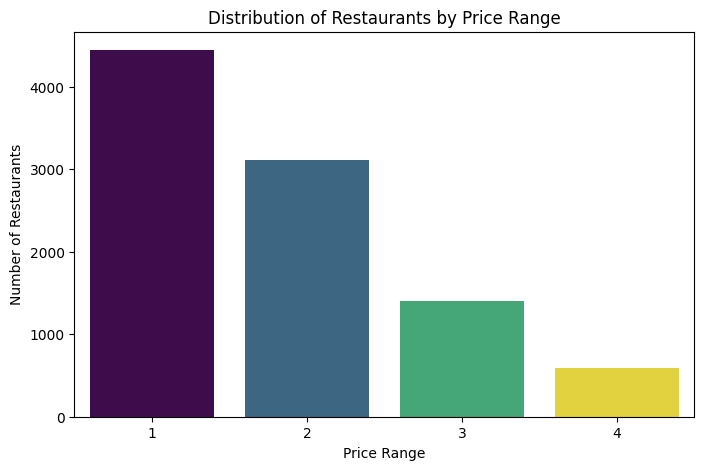

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Price range', hue='Price range',
              palette='viridis', legend=False)
plt.title("Distribution of Restaurants by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")
plt.show()

In [9]:

avg_rating = df.groupby('Price range')['Aggregate rating'].mean()

print("\nAverage Rating for Each Price Range:")
print(avg_rating.round(2))


Average Rating for Each Price Range:
Price range
1    2.00
2    2.94
3    3.68
4    3.82
Name: Aggregate rating, dtype: float64


In [10]:

highest_rating_range = avg_rating.idxmax()
highest_avg_rating = avg_rating.max()

rating_color = df[
    df['Price range'] == highest_rating_range
]['Rating color'].mode()[0]

print("\nPrice Range with Highest Average Rating:",
      highest_rating_range)

print("Highest Average Rating:", round(highest_avg_rating, 2))

print("Corresponding Rating Color:", rating_color)


Price Range with Highest Average Rating: 4
Highest Average Rating: 3.82
Corresponding Rating Color: Yellow


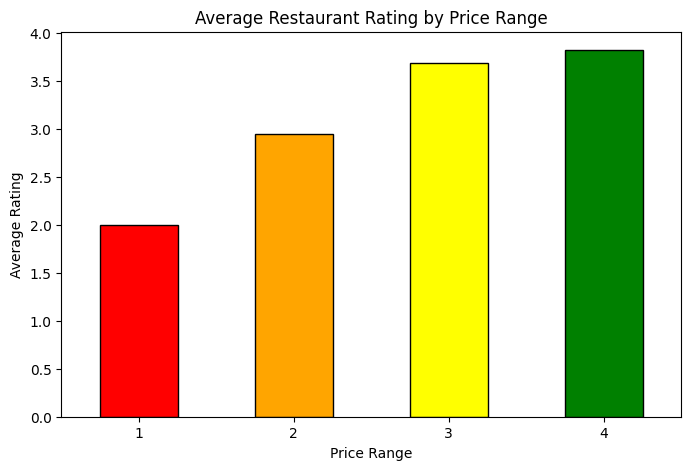

In [11]:
plt.figure(figsize=(8, 5))

avg_rating.plot(
    kind='bar',
    color=['red', 'orange', 'yellow', 'green'],
    edgecolor='black'
)

plt.title("Average Restaurant Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.show()

In [12]:
print("\n========== TASK 2 SUMMARY ==========")

print("Most Common Price Range:", most_common)

print("\nAverage Ratings:")
print(avg_rating.round(2))

print("\nHighest Rated Price Range:",
      highest_rating_range)

print("Highest Average Rating:",
      round(highest_avg_rating, 2))

print("Rating Color:", rating_color)


========== TASK 2 SUMMARY ==========
Most Common Price Range: 1

Average Ratings:
Price range
1    2.00
2    2.94
3    3.68
4    3.82
Name: Aggregate rating, dtype: float64

Highest Rated Price Range: 4
Highest Average Rating: 3.82
Rating Color: Yellow
